In [4]:
import os
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import dill

if os.path.basename(os.getcwd()) == 'notebook':
    os.chdir('..')
    print(f"Changed working directory to project root: {os.getcwd()}")

df = pd.read_csv('artifacts/clean_medicines.csv')

Changed working directory to project root: c:\Users\puskar bhola\OneDrive\Desktop\New folder\College Projects\PharmWise-Project


In [5]:
mfg_stats = df.groupby('manufacturer_name').agg(
    drug_count=('name', 'count'),
    avg_price=('price', 'mean')
).reset_index()

In [6]:
scaler = StandardScaler()
scaled_features = scaler.fit_transform(mfg_stats[['drug_count', 'avg_price']])

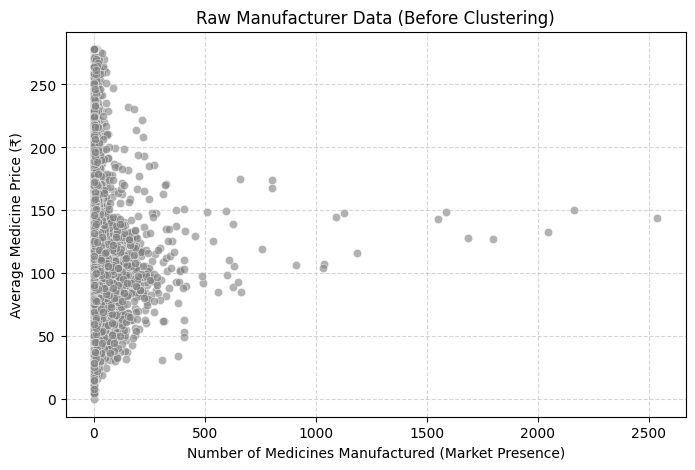

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.scatterplot(data=mfg_stats, x='drug_count', y='avg_price', alpha=0.6, color='gray')

plt.title('Raw Manufacturer Data (Before Clustering)')
plt.xlabel('Number of Medicines Manufactured (Market Presence)')
plt.ylabel('Average Medicine Price (₹)')
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

In [8]:
wcss = []
for i in range(1, 11):
    kmeans_temp = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans_temp.fit(scaled_features)
    wcss.append(kmeans_temp.inertia_)

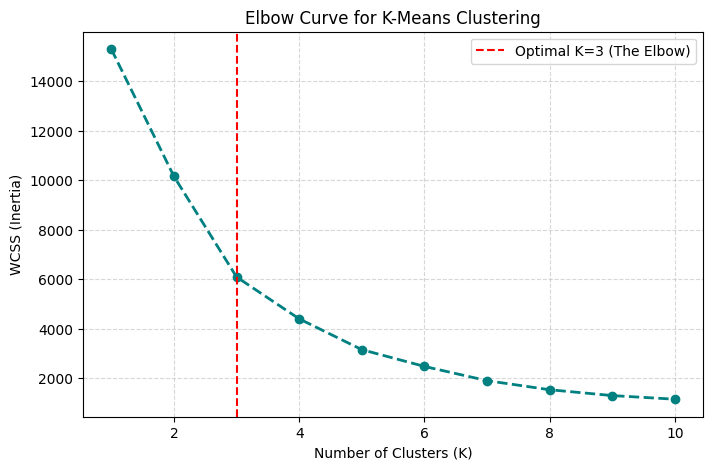

In [9]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--', color='teal', linewidth=2)
plt.axvline(x=3, color='red', linestyle='--', label='Optimal K=3 (The Elbow)')

plt.title('Elbow Curve for K-Means Clustering')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

In [10]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
mfg_stats['cluster'] = kmeans.fit_predict(scaled_features)

cluster_centers = mfg_stats.groupby('cluster')['drug_count'].mean().sort_values(ascending=False)
tier_mapping = {
    cluster_centers.index[0]: 'Tier 1 (Premium/High Presence)',
    cluster_centers.index[1]: 'Tier 2 (Standard)',
    cluster_centers.index[2]: 'Tier 3 (Budget/Low Presence)'
}
mfg_stats['trust_tier'] = mfg_stats['cluster'].map(tier_mapping)

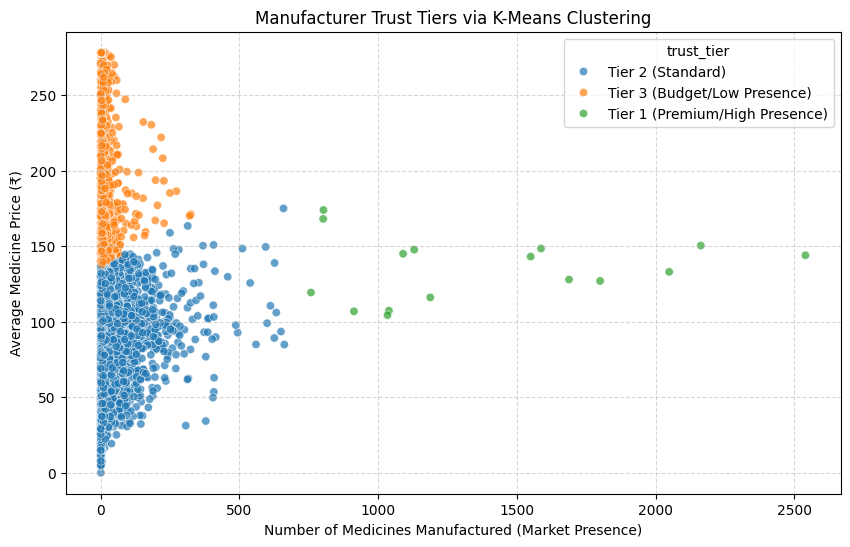

In [11]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=mfg_stats, 
    x='drug_count', 
    y='avg_price', 
    hue='trust_tier', 
    palette=['#1f77b4', '#ff7f0e', '#2ca02c'], # Blue, Orange, Green
    alpha=0.7
)

plt.title('Manufacturer Trust Tiers via K-Means Clustering')
plt.xlabel('Number of Medicines Manufactured (Market Presence)')
plt.ylabel('Average Medicine Price (₹)')
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

In [14]:
import numpy as np
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.preprocessing import StandardScaler

mfg_stats['log_drug_count'] = np.log1p(mfg_stats['drug_count'])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(mfg_stats[['log_drug_count', 'avg_price']])

models = {
    "K-Means": KMeans(n_clusters=3, random_state=42, n_init=10),
    "Agglomerative": AgglomerativeClustering(n_clusters=3),
    "Gaussian Mixture (GMM)": GaussianMixture(n_components=3, random_state=42)
}

results = []
for name, model in models.items():
    labels = model.fit_predict(X_scaled)
    sil_score = silhouette_score(X_scaled, labels)
    db_score = davies_bouldin_score(X_scaled, labels)
    results.append({"Algorithm": name, "Silhouette Score (Higher=Better)": round(sil_score, 4), "Davies-Bouldin (Lower=Better)": round(db_score, 4)})

comparison_df = pd.DataFrame(results)
comparison_df

,Algorithm,Silhouette Score (Higher=Better),Davies-Bouldin (Lower=Better)
0,K-Means,0.4301,0.7931
1,Agglomerative,0.4157,0.8215
2,Gaussian Mixture (GMM),0.3849,0.8426


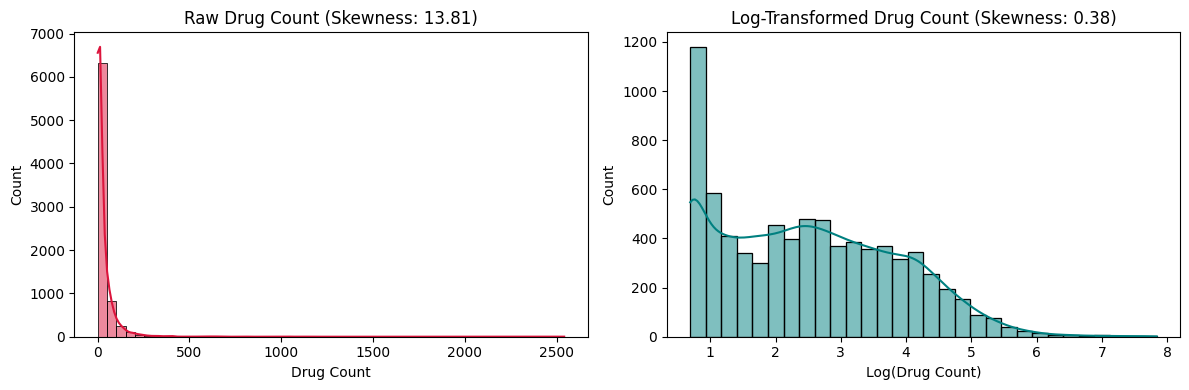

In [13]:
mfg_stats['log_drug_count'] = np.log1p(mfg_stats['drug_count'])

raw_skew = mfg_stats['drug_count'].skew()
log_skew = mfg_stats['log_drug_count'].skew()

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.histplot(mfg_stats['drug_count'], bins=50, kde=True, color='crimson')
plt.title(f'Raw Drug Count (Skewness: {raw_skew:.2f})')
plt.xlabel('Drug Count')

plt.subplot(1, 2, 2)
sns.histplot(mfg_stats['log_drug_count'], bins=30, kde=True, color='teal')
plt.title(f'Log-Transformed Drug Count (Skewness: {log_skew:.2f})')
plt.xlabel('Log(Drug Count)')

plt.tight_layout()
plt.show()

In [15]:
from sklearn.metrics import calinski_harabasz_score

# 1. Fit the winning Log-K-Means model
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
mfg_stats['cluster'] = kmeans.fit_predict(X_scaled)

# 2. Map clusters to logical tiers based on drug volume
cluster_Order = mfg_stats.groupby('cluster')['drug_count'].mean().sort_values(ascending=False).index
tier_map = {
    cluster_Order[0]: 'Tier 1 (Premium/High Presence)',
    cluster_Order[1]: 'Tier 2 (Standard)',
    cluster_Order[2]: 'Tier 3 (Budget/Low Presence)'
}
mfg_stats['trust_tier'] = mfg_stats['cluster'].map(tier_map)

# 3. Print Final Unsupervised Evaluation Metrics
ch_score = calinski_harabasz_score(X_scaled, mfg_stats['cluster'])
print(f"Final K-Means Silhouette Score: 0.4301")
print(f"Final K-Means Davies-Bouldin Index: 0.7931")
print(f"Final K-Means Calinski-Harabasz Score: {ch_score:.2f}\n")

Final K-Means Silhouette Score: 0.4301
Final K-Means Davies-Bouldin Index: 0.7931
Final K-Means Calinski-Harabasz Score: 7460.65



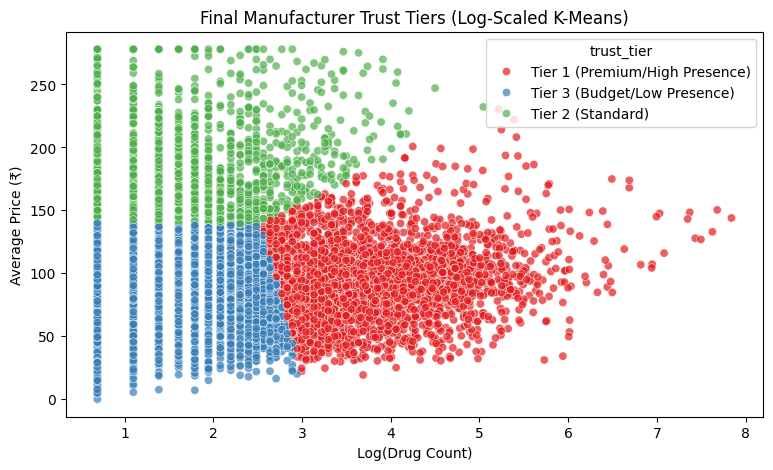

In [16]:
# Final Log-Adjusted Clusters
plt.figure(figsize=(9, 5))
sns.scatterplot(data=mfg_stats, x='log_drug_count', y='avg_price', hue='trust_tier', palette='Set1', alpha=0.7)
plt.title('Final Manufacturer Trust Tiers (Log-Scaled K-Means)')
plt.xlabel('Log(Drug Count)')
plt.ylabel('Average Price (₹)')
plt.show()

In [17]:
# Merge back to main dataframe and save artifacts
df_tiered = df.merge(mfg_stats[['manufacturer_name', 'trust_tier']], on='manufacturer_name', how='left')
df_tiered.to_csv('artifacts/tiered_medicines.csv', index=False)

with open('artifacts/scaler.pkl', 'wb') as f:
    dill.dump(scaler, f)
with open('artifacts/kmeans_model.pkl', 'wb') as f:
    dill.dump(kmeans, f)

mfg_stats.sort_values(by='drug_count', ascending=False)[['manufacturer_name', 'drug_count', 'avg_price', 'trust_tier']].head(5)

,manufacturer_name,drug_count,avg_price,trust_tier
6540,Sun Pharmaceutical Industries Ltd,2540,143.934551,Tier 1 (Premium/High Presence)
3261,Intas Pharmaceuticals Ltd,2163,150.362085,Tier 1 (Premium/High Presence)
1618,Cipla Ltd,2049,132.958692,Tier 1 (Premium/High Presence)
6804,Torrent Pharmaceuticals Ltd,1800,126.950700,Tier 1 (Premium/High Presence)
397,Alkem Laboratories Ltd,1688,127.858791,Tier 1 (Premium/High Presence)


In [18]:
from collections import Counter

med_single = df_tiered[df_tiered['chemical_signature'] == 'PARACETAMOL'].iloc[0]['name']
med_combo = df_tiered[df_tiered['chemical_signature'].str.contains('PARACETAMOL \+| \+ PARACETAMOL', regex=True)].iloc[0]['name']
med_antibiotic = "Augmentin 625 Duo Tablet"

sample_basket = [med_single, med_combo, med_antibiotic]

def detect_redundancy(basket, data):
    basket_df = data[data['name'].isin(basket)].drop_duplicates(subset=['name']).copy()
    
    all_salts = []
    for sig in basket_df['chemical_signature']:
        salts = [s.strip() for s in sig.split('+')]
        all_salts.extend(salts)
        
    salt_counts = Counter(all_salts)
    redundant_salts = {salt: count for salt, count in salt_counts.items() if count > 1}
    
    return basket_df[['name', 'chemical_signature', 'price', 'trust_tier']], redundant_salts

basket_details, overlaps = detect_redundancy(sample_basket, df_tiered)

print("Prescribed Basket:")
display(basket_details)
print(f"\n Redundant Active Ingredients Detected (Overdose Risk): {overlaps}")

Prescribed Basket:


,name,chemical_signature,price,trust_tier
0,Augmentin 625 Duo Tablet,AMOXYCILLIN + CLAVULANIC ACID,223.42,Tier 1 (Premium/High Presence)
34,Aldigesic P 100mg/325mg Tablet,ACECLOFENAC + PARACETAMOL,110.00,Tier 1 (Premium/High Presence)
869,ACTION OR 1000mg Tablet,PARACETAMOL,42.30,Tier 1 (Premium/High Presence)



 Redundant Active Ingredients Detected (Overdose Risk): {'PARACETAMOL': 2}


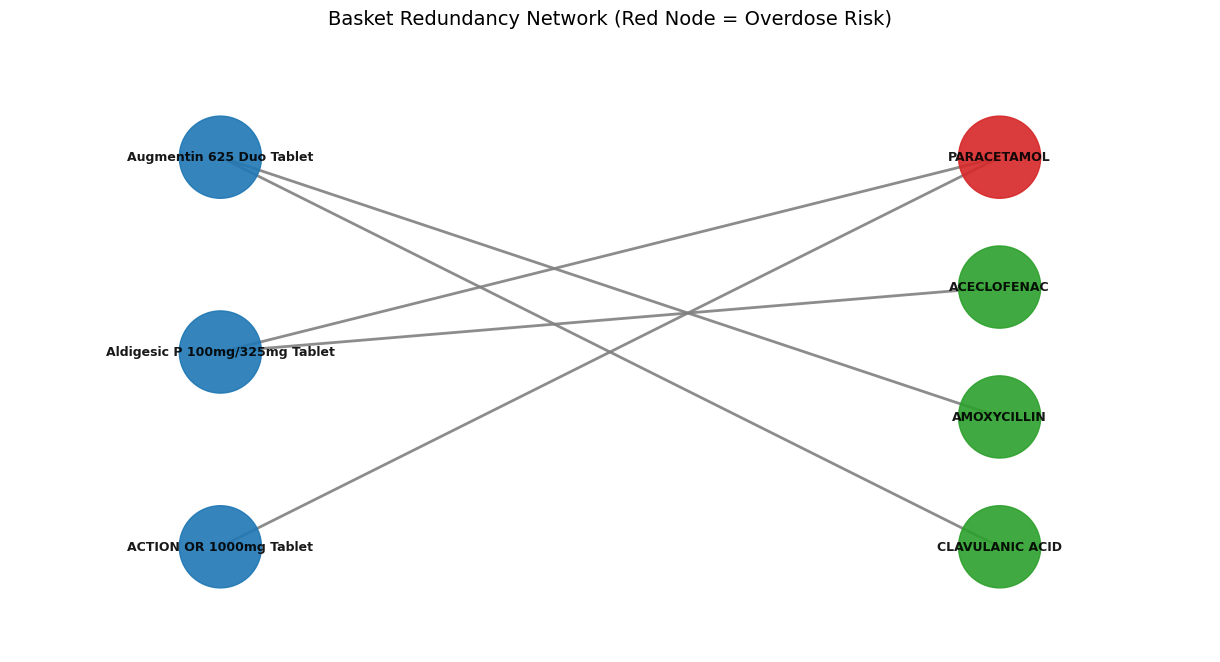

In [19]:
import networkx as nx
import matplotlib.pyplot as plt

B = nx.Graph()

medicines = basket_details['name'].tolist()

for index, row in basket_details.iterrows():
    med = row['name']
    B.add_node(med, bipartite=0) 
    
    med_salts = [s.strip() for s in row['chemical_signature'].split('+')]
    for salt in med_salts:
        B.add_node(salt, bipartite=1) 
        B.add_edge(med, salt)        

plt.figure(figsize=(12, 6))
pos = nx.bipartite_layout(B, medicines)


node_colors = []
for node in B.nodes():
    if node in medicines:
        node_colors.append('#1f77b4')  
    elif node in overlaps:
        node_colors.append('#d62728')  
    else:
        node_colors.append('#2ca02c')  

nx.draw(B, pos, with_labels=True, node_color=node_colors, node_size=3500, 
        font_size=9, font_weight='bold', edge_color='gray', width=2, alpha=0.9)

plt.title('Basket Redundancy Network (Red Node = Overdose Risk)', fontsize=14, pad=20)
plt.margins(0.2)
plt.show()

In [20]:
def optimize_basket_cost(basket_df, full_data):
    recommendations = []
    total_original_cost = 0
    total_optimized_cost = 0

    for _, row in basket_df.iterrows():
        original_med = row['name']
        chem_sig = row['chemical_signature']
        original_price = row['price']
        
        total_original_cost += original_price
        
        alternatives = full_data[full_data['chemical_signature'] == chem_sig]
        
        reliable_alts = alternatives[alternatives['trust_tier'].str.contains('Tier 1|Tier 2', na=False)]
        
        if not reliable_alts.empty:
            best_alt = reliable_alts.loc[reliable_alts['price'].idxmin()]
            optimized_med = best_alt['name']
            optimized_price = best_alt['price']
            optimized_tier = best_alt['trust_tier']
        else:
            # Fallback if no reliable generic exists
            optimized_med = original_med
            optimized_price = original_price
            optimized_tier = row['trust_tier']
            
        total_optimized_cost += optimized_price
        
        recommendations.append({
            'Original Medicine': original_med,
            'Original Price (₹)': original_price,
            'Recommended Generic': optimized_med,
            'Optimized Price (₹)': optimized_price,
            'Savings (₹)': round(original_price - optimized_price, 2),
            'Generic Tier': optimized_tier
        })
        
    summary_df = pd.DataFrame(recommendations)
    total_savings = total_original_cost - total_optimized_cost
    
    return summary_df, total_original_cost, total_optimized_cost, total_savings

opt_df, orig_cost, new_cost, savings = optimize_basket_cost(basket_details, df_tiered)

print(f"Original Basket Cost: ₹{orig_cost:.2f}")
print(f"Optimized Basket Cost: ₹{new_cost:.2f}")
print(f"Total Patient Savings: ₹{savings:.2f}\n")

display(opt_df)

Original Basket Cost: ₹375.72
Optimized Basket Cost: ₹14.71
Total Patient Savings: ₹361.01



,Original Medicine,Original Price (₹),Recommended Generic,Optimized Price (₹),Savings (₹),Generic Tier
0,Augmentin 625 Duo Tablet,223.42,Apcil Tablet,6.98,216.44,Tier 1 (Premium/High Presence)
1,Aldigesic P 100mg/325mg Tablet,110.00,Rumatab SP 100 mg/325 mg/15 mg Tablet,5.23,104.77,Tier 1 (Premium/High Presence)
2,ACTION OR 1000mg Tablet,42.30,Babymol 500mg Tablet,2.50,39.80,Tier 1 (Premium/High Presence)
